In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load dataset
df = pd.read_csv("Zomato Restaurant Dataset.csv")
print("Original dataset shape:", df.shape)
display(df.head())

Original dataset shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

In [4]:
# Clean text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )
    df[col] = df[col].replace("", np.nan)

In [5]:
# Remove duplicate rows
df = df.drop_duplicates()

In [6]:
# Convert numeric columns
numeric_cols = [
    "aggregate_rating", "votes", "price_range",
    "average_cost_for_two", "latitude", "longitude"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [7]:
# Check missing values
print("Missing values:")
display(df.isnull().sum().sort_values(ascending=False))

Missing values:


cuisines                9
restaurant_name         0
country_code            0
city                    0
restaurant_id           0
address                 0
locality                0
longitude               0
locality_verbose        0
latitude                0
average_cost_for_two    0
currency                0
has_table_booking       0
has_online_delivery     0
is_delivering_now       0
switch_to_order_menu    0
price_range             0
aggregate_rating        0
rating_color            0
rating_text             0
votes                   0
dtype: int64

In [8]:
# Remove rows without essential information
df = df.dropna(subset=["restaurant_name", "city"])

In [9]:
# Mark missing cuisines
df["cuisines"] = df["cuisines"].fillna("Unknown")

In [10]:
# Mark invalid ratings and price ranges as missing
df.loc[~df["aggregate_rating"].between(0, 5), "aggregate_rating"] = np.nan
df.loc[~df["price_range"].isin([1, 2, 3, 4]), "price_range"] = np.nan

In [11]:
print("Cleaned dataset shape:", df.shape)
display(df.head())

Cleaned dataset shape: (9551, 21)


,restaurant_id,restaurant_name,country_code,city,address,locality,locality_verbose,longitude,latitude,cuisines,...,currency,has_table_booking,has_online_delivery,is_delivering_now,switch_to_order_menu,price_range,aggregate_rating,rating_color,rating_text,votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3.0,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3.0,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4.0,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4.0,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4.0,4.8,Dark Green,Excellent,229


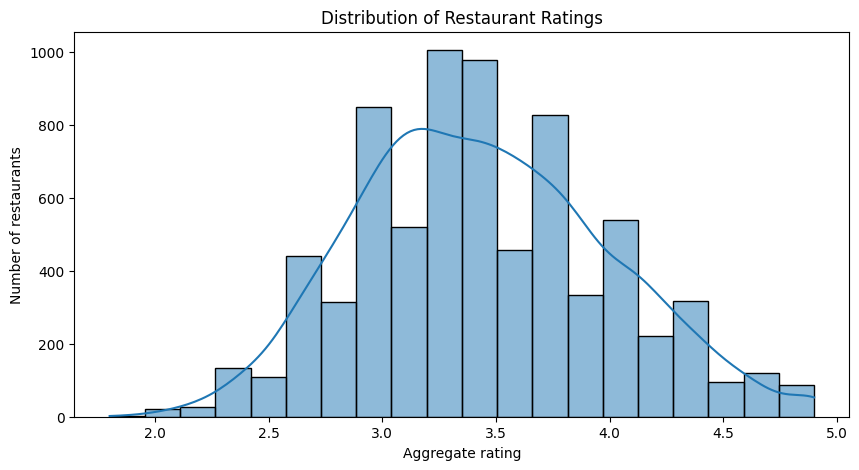

In [13]:
#Restaurant ratings distribution
rated = df[df["aggregate_rating"] > 0]
plt.figure(figsize=(10, 5))
sns.histplot(data=rated, x="aggregate_rating", bins=20, kde=True)
plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Aggregate rating")
plt.ylabel("Number of restaurants")
plt.show()

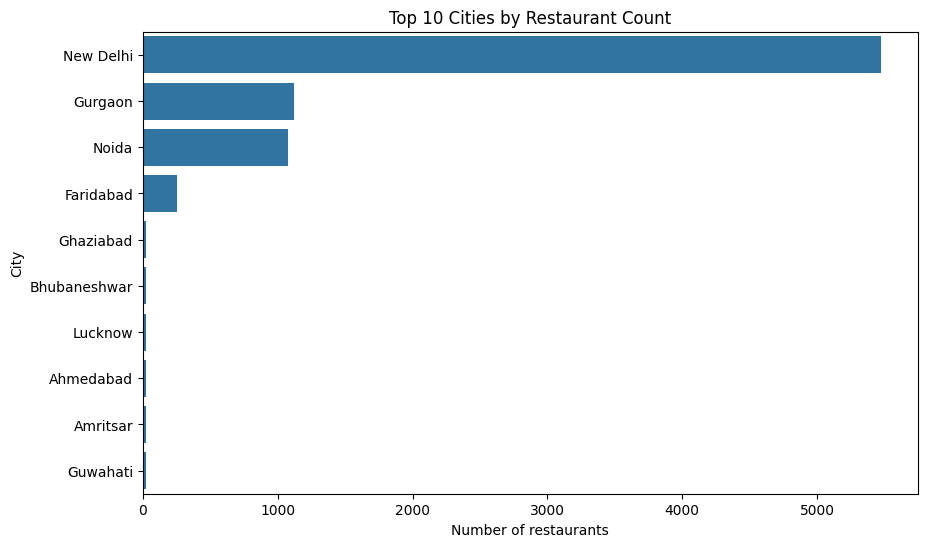

In [14]:
#top 10 cities
top_cities = df["city"].value_counts().head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_cities.values, y=top_cities.index)
plt.title("Top 10 Cities by Restaurant Count")
plt.xlabel("Number of restaurants")
plt.ylabel("City")
plt.show()

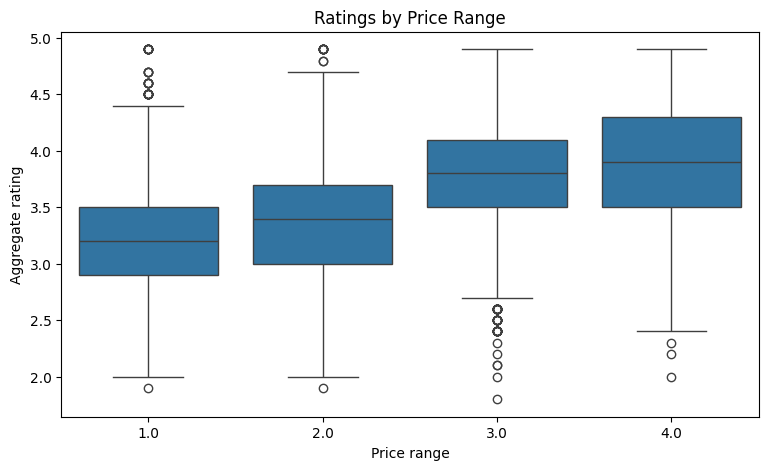

In [15]:
#Ratings by price range
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=rated,
    x="price_range",
    y="aggregate_rating"
)
plt.title("Ratings by Price Range")
plt.xlabel("Price range")
plt.ylabel("Aggregate rating")
plt.show()

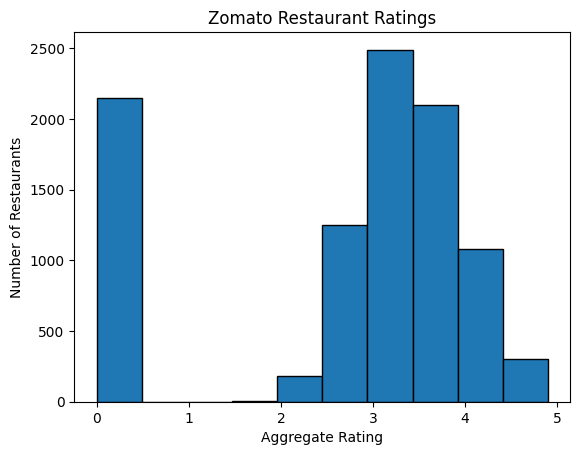

In [20]:
#Restaurant Ratings
df = pd.read_csv("Zomato Restaurant Dataset.csv")
plt.hist(df["Aggregate rating"], bins=10, edgecolor="black")
plt.title("Zomato Restaurant Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")
plt.show()

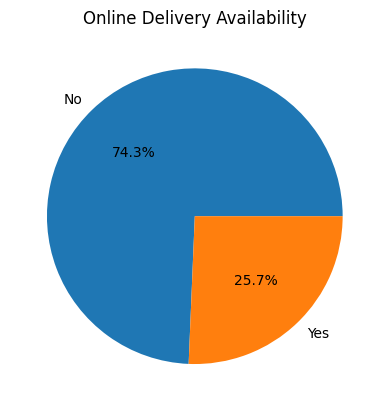

In [21]:
#Online Delivery Availability
df["Has Online delivery"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=["No", "Yes"]
)
plt.title("Online Delivery Availability")
plt.ylabel("")
plt.show()